## VOLTA

## 1. Setup & Load  


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Plot settings (shared by all plots in this notebook)
plt.rcParams["figure.figsize"] = (14, 5)
plt.rcParams["font.size"] = 10

energy = pd.read_csv("../data/raw/energy_dataset.csv")
weather = pd.read_csv("../data/raw/weather_features.csv")

print("Energy:", energy.shape)
print("Weather:", weather.shape)

Energy: (35064, 29)
Weather: (178396, 17)


## Check Columns & Structure

In [2]:
display(energy.head())
display(weather.head())

,time,generation biomass,generation fossil brown coal/lignite,generation fossil coal-derived gas,generation fossil gas,generation fossil hard coal,generation fossil oil,generation fossil oil shale,generation fossil peat,generation geothermal,...,generation waste,generation wind offshore,generation wind onshore,forecast solar day ahead,forecast wind offshore eday ahead,forecast wind onshore day ahead,total load forecast,total load actual,price day ahead,price actual
0,2015-01-01 00:00:00+01:00,447.0,329.0,0.0,4844.0,4821.0,162.0,0.0,0.0,0.0,...,196.0,0.0,6378.0,17.0,NaN,6436.0,26118.0,25385.0,50.10,65.41
1,2015-01-01 01:00:00+01:00,449.0,328.0,0.0,5196.0,4755.0,158.0,0.0,0.0,0.0,...,195.0,0.0,5890.0,16.0,NaN,5856.0,24934.0,24382.0,48.10,64.92
2,2015-01-01 02:00:00+01:00,448.0,323.0,0.0,4857.0,4581.0,157.0,0.0,0.0,0.0,...,196.0,0.0,5461.0,8.0,NaN,5454.0,23515.0,22734.0,47.33,64.48
3,2015-01-01 03:00:00+01:00,438.0,254.0,0.0,4314.0,4131.0,160.0,0.0,0.0,0.0,...,191.0,0.0,5238.0,2.0,NaN,5151.0,22642.0,21286.0,42.27,59.32
4,2015-01-01 04:00:00+01:00,428.0,187.0,0.0,4130.0,3840.0,156.0,0.0,0.0,0.0,...,189.0,0.0,4935.0,9.0,NaN,4861.0,21785.0,20264.0,38.41,56.04


,dt_iso,city_name,temp,temp_min,temp_max,pressure,humidity,wind_speed,wind_deg,rain_1h,rain_3h,snow_3h,clouds_all,weather_id,weather_main,weather_description,weather_icon
0,2015-01-01 00:00:00+01:00,Valencia,270.475,270.475,270.475,1001,77,1,62,0.0,0.0,0.0,0,800,clear,sky is clear,01n
1,2015-01-01 01:00:00+01:00,Valencia,270.475,270.475,270.475,1001,77,1,62,0.0,0.0,0.0,0,800,clear,sky is clear,01n
2,2015-01-01 02:00:00+01:00,Valencia,269.686,269.686,269.686,1002,78,0,23,0.0,0.0,0.0,0,800,clear,sky is clear,01n
3,2015-01-01 03:00:00+01:00,Valencia,269.686,269.686,269.686,1002,78,0,23,0.0,0.0,0.0,0,800,clear,sky is clear,01n
4,2015-01-01 04:00:00+01:00,Valencia,269.686,269.686,269.686,1002,78,0,23,0.0,0.0,0.0,0,800,clear,sky is clear,01n


In [3]:
print("ENERGY COLUMNS:")
print(energy.columns.tolist())

print("\nWEATHER COLUMNS:")
print(weather.columns.tolist())


ENERGY COLUMNS:
['time', 'generation biomass', 'generation fossil brown coal/lignite', 'generation fossil coal-derived gas', 'generation fossil gas', 'generation fossil hard coal', 'generation fossil oil', 'generation fossil oil shale', 'generation fossil peat', 'generation geothermal', 'generation hydro pumped storage aggregated', 'generation hydro pumped storage consumption', 'generation hydro run-of-river and poundage', 'generation hydro water reservoir', 'generation marine', 'generation nuclear', 'generation other', 'generation other renewable', 'generation solar', 'generation waste', 'generation wind offshore', 'generation wind onshore', 'forecast solar day ahead', 'forecast wind offshore eday ahead', 'forecast wind onshore day ahead', 'total load forecast', 'total load actual', 'price day ahead', 'price actual']

WEATHER COLUMNS:
['dt_iso', 'city_name', 'temp', 'temp_min', 'temp_max', 'pressure', 'humidity', 'wind_speed', 'wind_deg', 'rain_1h', 'rain_3h', 'snow_3h', 'clouds_all',

In [4]:
print("ENERGY INFO")
energy.info()
print("\nWEATHER INFO")
weather.info()

ENERGY INFO
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35064 entries, 0 to 35063
Data columns (total 29 columns):
 #   Column                                       Non-Null Count  Dtype  
---  ------                                       --------------  -----  
 0   time                                         35064 non-null  object 
 1   generation biomass                           35045 non-null  float64
 2   generation fossil brown coal/lignite         35046 non-null  float64
 3   generation fossil coal-derived gas           35046 non-null  float64
 4   generation fossil gas                        35046 non-null  float64
 5   generation fossil hard coal                  35046 non-null  float64
 6   generation fossil oil                        35045 non-null  float64
 7   generation fossil oil shale                  35046 non-null  float64
 8   generation fossil peat                       35046 non-null  float64
 9   generation geothermal                        35046 non-null 

## Convert Timestamps



In [5]:
# Keep the original data unchanged
energy_raw = energy.copy()
weather_raw = weather.copy()

# Convert timestamps to datetime
energy["time"] = pd.to_datetime(energy["time"], utc=True)
weather["dt_iso"] = pd.to_datetime(weather["dt_iso"], utc=True)

# Check time ranges
print("Energy start:", energy["time"].min())
print("Energy end:", energy["time"].max())

print("Weather start:", weather["dt_iso"].min())
print("Weather end:", weather["dt_iso"].max())

# Check data types
print("Energy time dtype:", energy["time"].dtype)
print("Weather time dtype:", weather["dt_iso"].dtype)

Energy start: 2014-12-31 23:00:00+00:00
Energy end: 2018-12-31 22:00:00+00:00
Weather start: 2014-12-31 23:00:00+00:00
Weather end: 2018-12-31 22:00:00+00:00
Energy time dtype: datetime64[ns, UTC]
Weather time dtype: datetime64[ns, UTC]


## Sort & Set Index


In [6]:
energy = energy.sort_values("time")
energy = energy.set_index("time")
energy.head(3)

,generation biomass,generation fossil brown coal/lignite,generation fossil coal-derived gas,generation fossil gas,generation fossil hard coal,generation fossil oil,generation fossil oil shale,generation fossil peat,generation geothermal,generation hydro pumped storage aggregated,...,generation waste,generation wind offshore,generation wind onshore,forecast solar day ahead,forecast wind offshore eday ahead,forecast wind onshore day ahead,total load forecast,total load actual,price day ahead,price actual
time,,,,,,,,,,,,,,,,,,,,,
2014-12-31 23:00:00+00:00,447.0,329.0,0.0,4844.0,4821.0,162.0,0.0,0.0,0.0,NaN,...,196.0,0.0,6378.0,17.0,NaN,6436.0,26118.0,25385.0,50.10,65.41
2015-01-01 00:00:00+00:00,449.0,328.0,0.0,5196.0,4755.0,158.0,0.0,0.0,0.0,NaN,...,195.0,0.0,5890.0,16.0,NaN,5856.0,24934.0,24382.0,48.10,64.92
2015-01-01 01:00:00+00:00,448.0,323.0,0.0,4857.0,4581.0,157.0,0.0,0.0,0.0,NaN,...,196.0,0.0,5461.0,8.0,NaN,5454.0,23515.0,22734.0,47.33,64.48


## Check Energy Timestamps


In [7]:
print("Sorted:", energy.index.is_monotonic_increasing)
print("Duplicate timestamps:", energy.index.duplicated().sum())
print(energy.index.to_series().diff().value_counts())

Sorted: True
Duplicate timestamps: 0
time
0 days 01:00:00    35063
Name: count, dtype: int64


## Check Weather Cities & Duplicates

In [8]:
print(weather["city_name"].value_counts())
print("Duplicate (time, city):", weather.duplicated(subset=["dt_iso", "city_name"]).sum())

city_name
Madrid        36267
Bilbao        35951
Seville       35557
 Barcelona    35476
Valencia      35145
Name: count, dtype: int64
Duplicate (time, city): 3076


## Inspect Weather Duplicates

In [9]:
dups = weather[weather.duplicated(subset=["dt_iso", "city_name"], keep=False)]
dups = dups.sort_values(["city_name", "dt_iso"])
dups.head(6)

,dt_iso,city_name,temp,temp_min,temp_max,pressure,humidity,wind_speed,wind_deg,rain_1h,rain_3h,snow_3h,clouds_all,weather_id,weather_main,weather_description,weather_icon
109256,2015-03-20 20:00:00+00:00,Barcelona,286.81,282.59,291.48,1013,76,12,50,0.3,0.0,0.0,40,500,rain,light rain,10n
109257,2015-03-20 20:00:00+00:00,Barcelona,286.81,282.59,291.48,1013,76,12,50,0.3,0.0,0.0,40,301,drizzle,drizzle,09n
111170,2015-06-08 13:00:00+00:00,Barcelona,299.47,291.48,304.82,1017,57,3,180,12.0,0.0,0.0,20,503,rain,very heavy rain,10d
111171,2015-06-08 13:00:00+00:00,Barcelona,299.47,291.48,304.82,1017,57,3,180,12.0,0.0,0.0,20,211,thunderstorm,thunderstorm,11d
111172,2015-06-08 14:00:00+00:00,Barcelona,297.59,292.04,300.37,1017,54,2,170,3.0,0.0,0.0,20,502,rain,heavy intensity rain,10d
111173,2015-06-08 14:00:00+00:00,Barcelona,297.59,292.04,300.37,1017,54,2,170,3.0,0.0,0.0,20,211,thunderstorm,thunderstorm,11d


In [10]:
num_cols = ["temp","temp_min","temp_max","pressure","humidity",
            "wind_speed","wind_deg","rain_1h","rain_3h","snow_3h","clouds_all"]
dup_rows = weather[weather.duplicated(subset=["dt_iso","city_name"], keep=False)]
diff = dup_rows.groupby(["dt_iso","city_name"])[num_cols].nunique().max(axis=1)
print("Duplicate pairs with different numeric values:", (diff > 1).sum())

Duplicate pairs with different numeric values: 0


## Key Columns

| Column | Meaning | Unit |
|---|---|---|
| time / dt_iso | Timestamp (converted to UTC) | UTC hour |
| generation solar / wind onshore / wind offshore | Actual electricity generated | MW |
| generation fossil gas / hard coal / brown coal-lignite / oil | Actual electricity generated | MW |
| total load actual | Actual electricity demand | MW |
| total load forecast | Official day-ahead demand forecast | MW |
| forecast solar / wind onshore day ahead | Official day-ahead generation forecasts | MW |
| price actual | Actual electricity price | EUR/MWh |
| price day ahead | Day-ahead electricity market price | EUR/MWh |
| temp, temp_min, temp_max | Temperature (per city) | Kelvin |
| pressure | Air pressure | hPa |
| humidity, clouds_all | Humidity, cloud cover | % |
| wind_speed, wind_deg | Wind speed, direction | m/s, degrees |
| rain_1h, rain_3h, snow_3h | Precipitation | mm |

Units are the usual ones for this dataset and should be confirmed against the dataset description.

## Track A — Key Findings

- Energy data contains 35,064 hourly records, from 2014-12-31 23:00 UTC to 2018-12-31 22:00 UTC.
- Energy timestamps are sorted, with no duplicate or missing hours within the recorded period.
- Weather data covers five cities and approximately the same period as the energy data.
- Two Energy columns are completely empty: `generation hydro pumped storage aggregated` and `forecast wind offshore day ahead`.
- `total load actual` has 36 missing values (35,028 non-null out of 35,064).
- Weather has no missing values reported by `info()`.
- Weather has 3,076 duplicate (hour, city) entries.
- Initial inspection shows that some duplicate weather records have identical numerical measurements but different weather descriptions.
- Further checks are needed to confirm whether numerical measurements differ in other duplicated records.
- No duplicates or missing values have been removed or filled yet.

# Track B: Time Series Data Visualization
**Author:** Mohammed Ghannam Alyami
**Project:** VOLTA — Energy Pressure Forecasting
**Task:** Exploratory Data Analysis (EDA) & Trend Analysis

Objective: analyze trends, seasonality, daily/weekly patterns and anomalies across the four main targets:
1. Electricity Demand (`total load actual`)
2. Price (`price actual`)
3. Renewable Generation
4. Fossil Generation

In [17]:
# Set plotting style
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

# Track A already loaded, converted and sorted the data: reuse it
df = energy.copy()

# 2. Correct Renewable Generation Columns (Actual generation only)
# NOTE: biomass moved here from fossil (it is classified as renewable)
renewable_cols = [
    'generation hydro run-of-river and poundage',
    'generation hydro water reservoir',
    'generation solar',
    'generation wind onshore',
    'generation biomass'
]

# 3. Correct Fossil Generation Columns (Actual generation only)
fossil_cols = [
    'generation fossil brown coal/lignite',
    'generation fossil gas',
    'generation fossil hard coal',
    'generation fossil oil'
]

# Calculate exact total generation for Renewable and Fossil
df['renewable_total'] = df[renewable_cols].sum(axis=1)
df['fossil_total'] = df[fossil_cols].sum(axis=1)

print("Data successfully loaded!")
print(f"Time Period: {df.index.min()} to {df.index.max()}")
print(f"Renewable actual columns count: {len(renewable_cols)}")
print(f"Fossil actual columns count: {len(fossil_cols)}")

Data successfully loaded!
Time Period: 2014-12-31 23:00:00+00:00 to 2018-12-31 22:00:00+00:00
Renewable actual columns count: 5
Fossil actual columns count: 4


## 1. Renewable vs Fossil Generation Trends (2015 – 2018)
*Question:* How do Renewable and Fossil energy generations compare over time, and do they show complementary seasonal patterns?

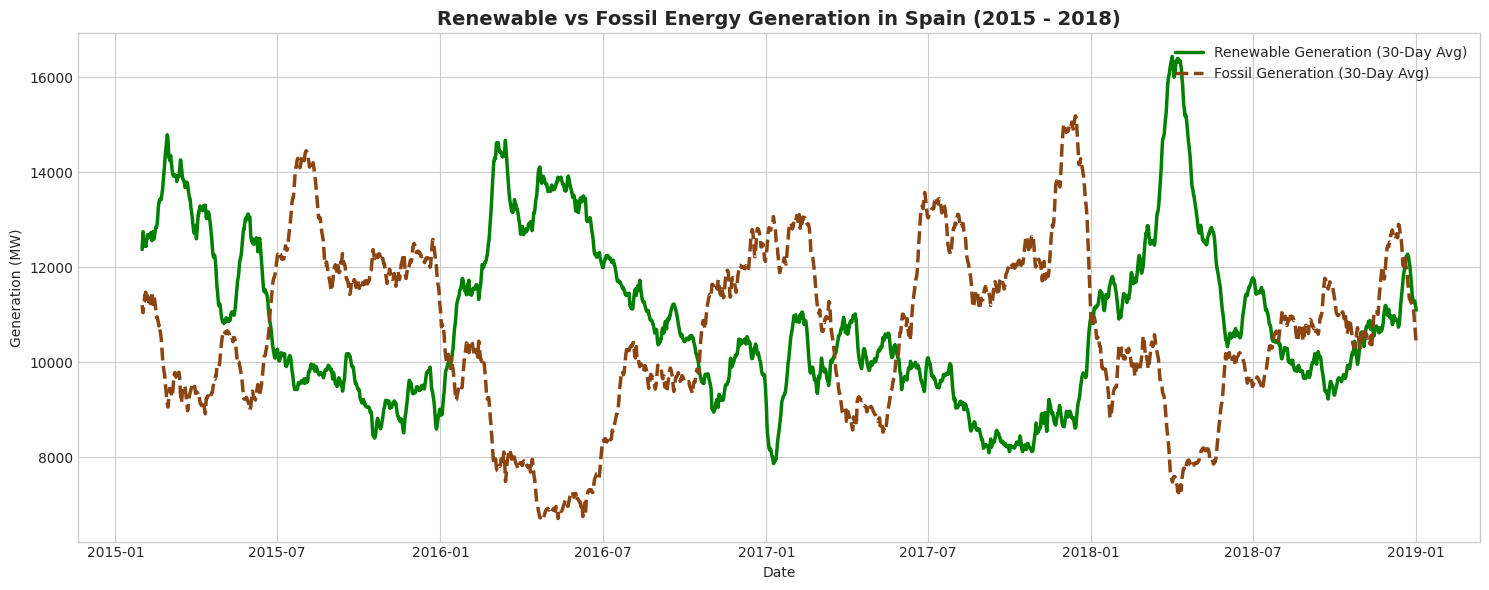

In [18]:
# Plot Renewable vs Fossil Generation over time with 30-day moving average
fig, ax = plt.subplots(figsize=(15, 6))

# 30-day Moving Averages for clean visual comparison
ax.plot(df['renewable_total'].rolling(window=24*30).mean(), color='green', linewidth=2.5, label='Renewable Generation (30-Day Avg)')
ax.plot(df['fossil_total'].rolling(window=24*30).mean(), color='saddlebrown', linewidth=2.5, linestyle='--', label='Fossil Generation (30-Day Avg)')

ax.set_title('Renewable vs Fossil Energy Generation in Spain (2015 - 2018)', fontsize=14, fontweight='bold')
ax.set_ylabel('Generation (MW)')
ax.set_xlabel('Date')
ax.legend(loc='upper right')
plt.tight_layout()
plt.savefig('renewable_vs_fossil_trend.png', dpi=300)
plt.show()

## 2. Weekly & Hourly Demand Proof
*Question:* Can we clearly prove that Demand drops on weekends and peaks at specific hours of the day?

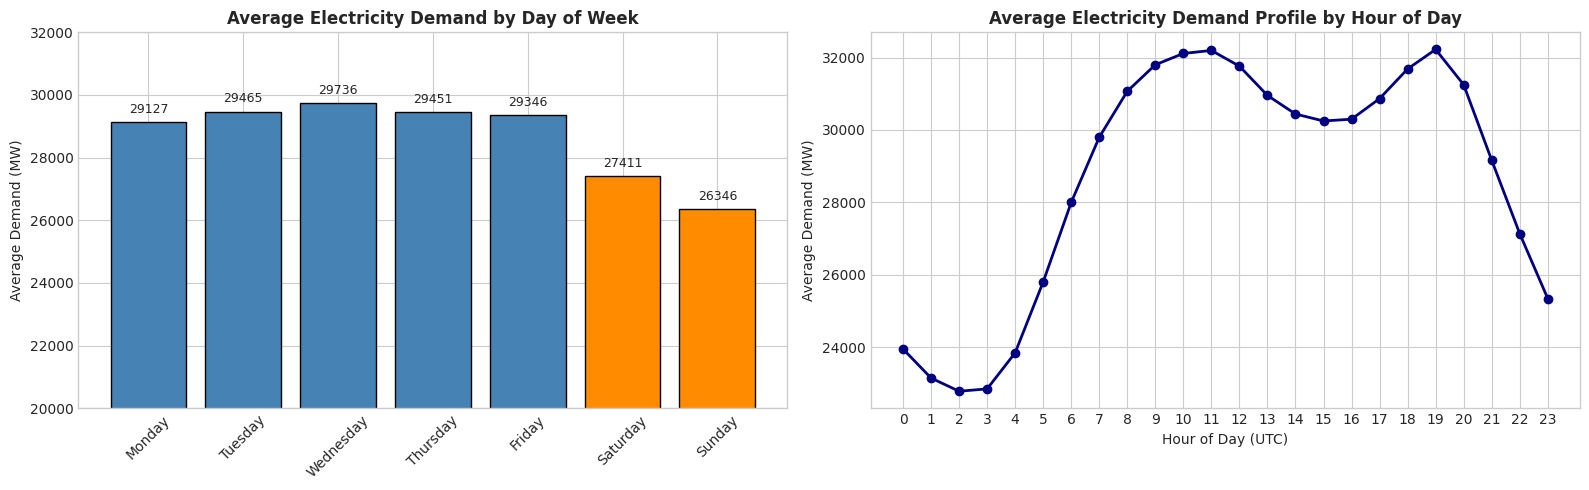

In [19]:
# Create Day of Week and Hour features for grouping
df['day_of_week'] = df.index.day_name()
df['hour'] = df.index.hour

# Order days chronologically starting from Monday
days_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# 1. Bar Chart: Average Demand by Day of Week (Proves weekend drop)
avg_day = df.groupby('day_of_week')['total load actual'].mean().reindex(days_order)
bars = axes[0].bar(avg_day.index, avg_day.values, color=['steelblue']*5 + ['darkorange']*2, edgecolor='black')
axes[0].set_title('Average Electricity Demand by Day of Week', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Average Demand (MW)')
axes[0].tick_params(axis='x', rotation=45)
axes[0].set_ylim(20000, 32000)

# Add value labels above bars
for bar in bars:
    yval = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width()/2, yval + 200, f'{int(yval)}', ha='center', va='bottom', fontsize=9)

# 2. Line Chart: Average Demand by Hour of Day (Proves daily peaks)
avg_hour = df.groupby('hour')['total load actual'].mean()
axes[1].plot(avg_hour.index, avg_hour.values, color='navy', marker='o', linewidth=2)
axes[1].set_title('Average Electricity Demand Profile by Hour of Day', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Hour of Day (UTC)')
axes[1].set_ylabel('Average Demand (MW)')
axes[1].set_xticks(range(0, 24))
axes[1].grid(True)

plt.tight_layout()
plt.savefig('demand_patterns_proof.png', dpi=300)
plt.show()

## 3. Sudden Changes & Unusual Events (Spikes & Anomalies)
*Question:* Are there extreme price spikes or sudden anomalies in electricity demand that could affect model evaluation?

Price Spike Threshold (99th percentile): 87.46 EUR/MWh
Total Hourly Spikes Detected: 351


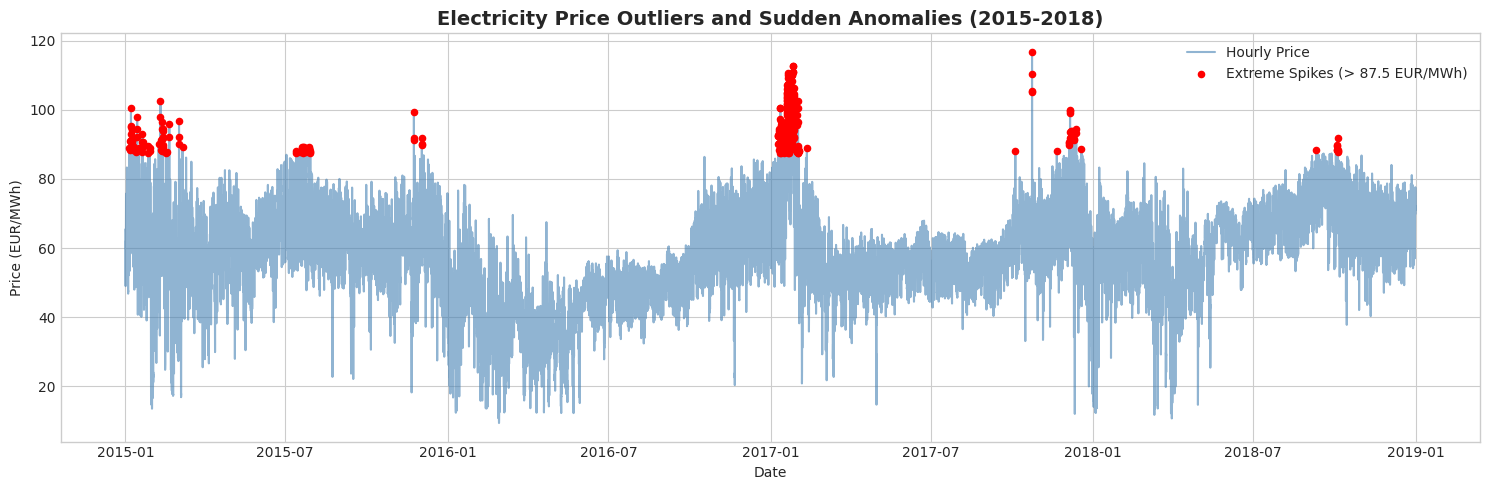

In [20]:
# Detect extreme price spikes (e.g., prices > 90th percentile or above 80 EUR/MWh)
price_threshold = df['price actual'].quantile(0.99)
spikes = df[df['price actual'] > price_threshold]

print(f"Price Spike Threshold (99th percentile): {price_threshold:.2f} EUR/MWh")
print(f"Total Hourly Spikes Detected: {len(spikes)}")

# Plotting Price Spikes and Extreme Anomalies
plt.figure(figsize=(15, 5))
plt.plot(df.index, df['price actual'], color='steelblue', alpha=0.6, label='Hourly Price')
plt.scatter(spikes.index, spikes['price actual'], color='red', s=20, zorder=5, label=f'Extreme Spikes (> {price_threshold:.1f} EUR/MWh)')

plt.title('Electricity Price Outliers and Sudden Anomalies (2015-2018)', fontsize=14, fontweight='bold')
plt.ylabel('Price (EUR/MWh)')
plt.xlabel('Date')
plt.legend()
plt.tight_layout()
plt.savefig('unusual_events_spikes.png', dpi=300)
plt.show()

## 4. Continuity Analysis: Missing Periods & Timestamp Gaps
*Question:* Are there missing hourly records or changes in the measurement time sequence across the 4-year period?

Total Expected Hours: 35064
Total Actual Rows in Dataset: 35064
Number of Missing Hourly Timestamps: 0


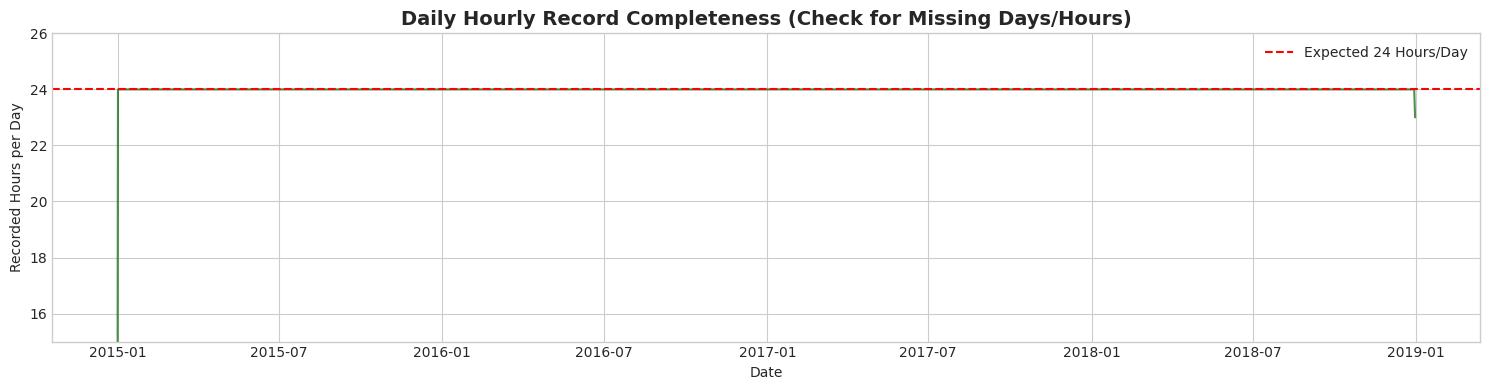

In [21]:
# Generate a complete hourly range from start date to end date
expected_range = pd.date_range(start=df.index.min(), end=df.index.max(), freq='h')

# Identify missing hourly timestamps
missing_timestamps = expected_range.difference(df.index)

print(f"Total Expected Hours: {len(expected_range)}")
print(f"Total Actual Rows in Dataset: {len(df)}")
print(f"Number of Missing Hourly Timestamps: {len(missing_timestamps)}")

# Plot hourly data density over time to inspect measurement consistency
hourly_counts = df.resample('D')['price actual'].count()

plt.figure(figsize=(15, 4))
plt.plot(hourly_counts.index, hourly_counts.values, color='darkgreen', alpha=0.7)
plt.axhline(24, color='red', linestyle='--', label='Expected 24 Hours/Day')

plt.title('Daily Hourly Record Completeness (Check for Missing Days/Hours)', fontsize=14, fontweight='bold')
plt.ylabel('Recorded Hours per Day')
plt.xlabel('Date')
plt.ylim(15, 26)
plt.legend()
plt.tight_layout()
plt.savefig('missing_periods_check.png', dpi=300)
plt.show()

## 5. Track B Final Findings & Recommendations

1. **4 Targets Covered:** Analyzed all 4 targets (Demand, Price, Renewable, Fossil).
2. **Long-Term & Seasonal Trends:** Electricity Demand exhibits strong seasonal consistency (Winter/Summer peaks), Renewable generation peaks in late winter and early spring and varies from year to year, whereas Price shows high volatility.
3. **Weekly Pattern Proof:** Average demand drops significantly on weekends (~26,300 MW on Sunday and ~27,400 MW on Saturday vs ~29,400 MW on weekdays).
4. **Daily Seasonality Proof:** Demand clearly peaks twice daily: around 11:00 AM UTC (morning business peak) and 7:00 PM UTC (evening residential peak).
5. **Data Quality & Continuity:** Time sequence is complete across all 35,064 hours (0 missing timestamps), making it ready for time-series splitting. Note: timestamps are complete, but `total load actual` has 36 missing values.